# 10. Dimensional analysis: the Buckingham pi theorem as linear algebra

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/10_dimensional_analysis.ipynb)

The Reynolds, Nusselt and Prandtl numbers are usually presented as facts to memorize. They can
be *derived*, from nothing more than a list of the variables that matter. The derivation is a
null-space calculation, the same operation that balanced a chemical reaction in notebook 4.

**Buckingham's theorem.** A relation between $n$ variables involving $k$ independent base
dimensions can be rewritten as a relation between $n - k$ dimensionless groups.

**Worked examples:** the period of a pendulum, drag on a sphere, pressure drop in a pipe,
convective heat transfer, and scaling a differential equation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 10.1 The idea, on the simplest example

**Problem.** On what can the period $T$ of a pendulum depend? Perhaps its length $L$, gravity
$g$ and the mass $m$ of the bob.

Write each variable's dimensions as exponents of mass, length and time, one column per variable:

In [2]:
#                         T   L   g   m
dim_matrix = sp.Matrix([[0,  0,  0,  1],     # mass
                        [0,  1,  1,  0],     # length
                        [1,  0, -2,  0]])    # time

A product $T^{a} L^{b} g^{c} m^{d}$ is dimensionless when the exponents satisfy
$\mathbf{D}\,(a, b, c, d)^T = \mathbf{0}$. Those exponent vectors form the null space.

In [3]:
dim_matrix.rank(), dim_matrix.nullspace()

⎛   ⎡⎡2 ⎤⎤⎞
⎜   ⎢⎢  ⎥⎥⎟
⎜   ⎢⎢-1⎥⎥⎟
⎜3, ⎢⎢  ⎥⎥⎟
⎜   ⎢⎢1 ⎥⎥⎟
⎜   ⎢⎢  ⎥⎥⎟
⎝   ⎣⎣0 ⎦⎦⎠

Four variables, rank three, so one group: exponents $(2, -1, 1, 0)$, that is $\Pi = T^2 g / L$.
With a single group the relation must be $\Pi = \text{constant}$, so

$$T = C\sqrt{L/g}.$$

The exponent of $m$ is zero: **the mass cannot appear**, because nothing else in the list could
cancel its dimension. All of this follows before writing a single equation of motion. (Solving
the equation gives $C = 2\pi$.)

In [4]:
assert list(dim_matrix.nullspace()[0].T) == [2, -1, 1, 0]

## 10.2 A reusable function

The null space gives *a* valid set of groups, but not necessarily the conventional one. The
usual hand method picks **repeating variables** (as many as there are base dimensions) and
combines each remaining variable with them. That is one small linear solve per group.

In [5]:
def pi_groups(dimensions, repeating):
    """Dimensionless groups by the method of repeating variables.

    dimensions: {symbol: exponents of the base dimensions, e.g. (M, L, T)}
    repeating:  the symbols to use as repeating variables
    """
    base = sp.Matrix([dimensions[v] for v in repeating]).T
    if base.rank() < base.rows:
        raise ValueError("the repeating variables do not span all base dimensions")
    groups = []
    for variable, exponents in dimensions.items():
        if variable in repeating:
            continue
        powers = base.solve(-sp.Matrix(exponents))       # cancel this variable's dimensions
        groups.append(variable * sp.Mul(*[r**p for r, p in zip(repeating, powers)]))
    return groups

## 10.3 Drag on a sphere

**Problem.** The drag force $F$ on a sphere depends on its diameter $D$, the speed $v$, and the
fluid density $\rho$ and viscosity $\mu$. Five variables and three dimensions give two groups.

In [6]:
F, D, v, rho, mu = sp.symbols("F D v rho mu", positive=True)

#        (M, L, T)
drag = {
    F:   (1, 1, -2),
    D:   (0, 1, 0),
    v:   (0, 1, -1),
    rho: (1, -3, 0),
    mu:  (1, -1, -1),
}
pi_groups(drag, repeating=[rho, v, D])

⎡   F       μ  ⎤
⎢───────, ─────⎥
⎢ 2    2  D⋅ρ⋅v⎥
⎣D ⋅ρ⋅v        ⎦

The first group is a drag coefficient (the conventional $C_D$ differs only by the factor
$\pi/8$) and the second is $1/Re$. So the five-variable problem collapses to one curve,
$C_D = f(Re)$.

**Why this matters.** Below, synthetic "measurements" of drag are generated for four very
different fluid and sphere combinations from a standard drag correlation, with 5 % noise.
Plotted in raw variables they look unrelated. Plotted as the two groups they fall on one line.

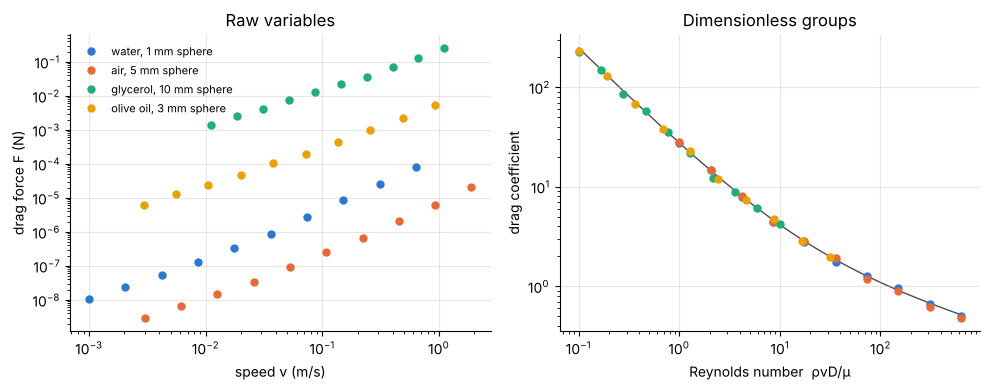

In [7]:
def drag_coefficient(Re):                       # Schiller–Naumann correlation, valid for Re < 1000
    return 24 / Re * (1 + 0.15 * Re**0.687)

rng = np.random.default_rng(seed=7)
systems = {                    # density (kg/m³), viscosity (Pa·s), diameter (m), range of log10(Re)
    "water, 1 mm sphere":      (998, 1.0e-3, 1e-3, (0, 2.8)),
    "air, 5 mm sphere":        (1.2, 1.8e-5, 5e-3, (0, 2.8)),
    "glycerol, 10 mm sphere":  (1260, 1.4, 1e-2, (-1, 1)),
    "olive oil, 3 mm sphere":  (910, 0.08, 3e-3, (-1, 1.5)),
}

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
for name, (dens, visc, diam, (low, high)) in systems.items():
    Re = np.logspace(low, high, 10)
    speed = Re * visc / (dens * diam)
    CD = drag_coefficient(Re) * rng.normal(1, 0.05, Re.size)
    force = CD * 0.5 * dens * speed**2 * np.pi * diam**2 / 4
    left.loglog(speed, force, "o", ms=5, label=name)
    right.loglog(Re, CD, "o", ms=5, label=name)
Re_line = np.logspace(-1, 2.8, 100)
right.loglog(Re_line, drag_coefficient(Re_line), color="0.3", lw=1, zorder=0)
left.set(xlabel="speed v (m/s)", ylabel="drag force F (N)", title="Raw variables")
right.set(xlabel="Reynolds number  ρvD/μ", ylabel="drag coefficient", title="Dimensionless groups")
left.legend(frameon=False, fontsize=8)
fig.tight_layout()

This collapse is the reason a wind-tunnel model can stand in for a full-size aircraft, and a
laboratory stirred tank for a production reactor: match the dimensionless groups and the
behaviour matches.

## 10.4 Pressure drop in a pipe

**Problem.** The pressure drop $\Delta P$ over a pipe of length $L$, diameter $D$ and wall
roughness $\varepsilon$, for a fluid with $\rho$, $\mu$ flowing at mean speed $v$.

In [8]:
dP, L, eps = sp.symbols("Delta_P L epsilon", positive=True)

pipe = {
    dP:  (1, -1, -2),
    L:   (0, 1, 0),
    D:   (0, 1, 0),
    eps: (0, 1, 0),
    v:   (0, 1, -1),
    rho: (1, -3, 0),
    mu:  (1, -1, -1),
}
pipe_groups = pi_groups(pipe, repeating=[rho, v, D])
pipe_groups

⎡Δ_P   L  ε    μ  ⎤
⎢────, ─, ─, ─────⎥
⎢   2  D  D  D⋅ρ⋅v⎥
⎣ρ⋅v              ⎦

Seven variables became four groups: an Euler number $\Delta P/(\rho v^2)$, the aspect ratio
$L/D$, the relative roughness $\varepsilon/D$ and $1/Re$. Since the pressure drop is
proportional to length in fully developed flow, the first two combine into the friction factor,
$f = \dfrac{\Delta P}{\tfrac12\rho v^2}\,\dfrac{D}{L} = \phi\!\left(Re, \varepsilon/D\right)$.
That function is the Moody chart, whose turbulent part was computed in notebook 2.

In [9]:
assert len(pipe_groups) == len(pipe) - 3
assert set(pipe_groups) == {dP / (rho * v**2), L / D, eps / D, mu / (rho * v * D)}

## 10.5 Heat transfer: a fourth base dimension

**Problem.** The heat-transfer coefficient $h$ for forced convection in a tube depends on
$D$, $v$, $\rho$, $\mu$, the thermal conductivity $k$ and the heat capacity $c_p$.
Temperature is now a base dimension, so the exponents are for (M, L, T, Θ).

In [10]:
h, k, cp = sp.symbols("h k c_p", positive=True)

convection = {
    h:   (1, 0, -3, -1),
    v:   (0, 1, -1, 0),
    cp:  (0, 2, -2, -1),
    D:   (0, 1, 0, 0),
    k:   (1, 1, -3, -1),
    mu:  (1, -1, -1, 0),
    rho: (1, -3, 0, 0),
}
Nu, Re_group, Pr = pi_groups(convection, repeating=[D, k, mu, rho])
Nu, Re_group, Pr

⎛D⋅h  D⋅ρ⋅v  cₚ⋅μ⎞
⎜───, ─────, ────⎟
⎝ k     μ     k  ⎠

Nusselt, Reynolds and Prandtl numbers, in that order. Every correlation of the form
$Nu = C\,Re^{a}Pr^{b}$, such as Dittus–Boelter, is a fit of the one function that dimensional
analysis says must exist.

In [11]:
assert (Nu, Re_group, Pr) == (h * D / k, rho * v * D / mu, cp * mu / k)

The choice of repeating variables is yours. A different choice gives different but equivalent
groups (products and powers of these). If the chosen variables cannot form a complete set,
the function says so:

In [12]:
try:
    pi_groups(convection, repeating=[D, v, mu, rho])      # none of these contains temperature
except ValueError as err:
    print("ValueError:", err)

ValueError: the repeating variables do not span all base dimensions


## 10.6 Scaling a differential equation

Dimensionless groups also appear when an equation is rewritten in scaled variables.

**Problem.** Scale the oscillator $m\ddot x + c\dot x + kx = 0$ using $x = x_0 X$ and
$t = t_c\,\tau$, and choose the time scale $t_c$ to make the equation as simple as possible.

By the chain rule $\dfrac{d}{dt} = \dfrac{1}{t_c}\dfrac{d}{d\tau}$:

In [13]:
m, c, k_s, x0, tc = sp.symbols("m c k x_0 t_c", positive=True)
tau = sp.symbols("tau")
X = sp.Function("X")

scaled = m * x0 / tc**2 * X(tau).diff(tau, 2) + c * x0 / tc * X(tau).diff(tau) + k_s * x0 * X(tau)
scaled = sp.expand(scaled / (k_s * x0))          # divide by the spring term
scaled

                       2       
                      d        
  d                 m⋅───(X(τ))
c⋅──(X(τ))              2      
  dτ                  dτ       
────────── + X(τ) + ───────────
  k⋅t_c                    2   
                      k⋅t_c    

In [14]:
# choose t_c so that the coefficient of the acceleration is exactly 1
tc_choice = sp.solve(sp.Eq(scaled.coeff(X(tau).diff(tau, 2)), 1), tc)[0]
dimensionless = sp.simplify(scaled.subs(tc, tc_choice))
tc_choice, dimensionless

⎛      d                          ⎞
⎜    c⋅──(X(τ))           2       ⎟
⎜√m    dτ                d        ⎟
⎜──, ────────── + X(τ) + ───(X(τ))⎟
⎜√k    √k⋅√m               2      ⎟
⎝                        dτ       ⎠

The natural time scale is $\sqrt{m/k} = 1/\omega_n$, and three parameters ($m$, $c$, $k$) have
collapsed into one, $c/\sqrt{mk} = 2\zeta$. The whole family of oscillators is described by the
damping ratio alone, which is why notebooks 6 and 7 needed only $\zeta$.

In [15]:
damping_group = dimensionless.coeff(X(tau).diff(tau))
assert sp.simplify(damping_group - c / sp.sqrt(m * k_s)) == 0

## Exercises

1. The speed $c$ of waves on deep water might depend on wavelength $\lambda$, gravity $g$ and
   density $\rho$. Find the group. Does density matter?
2. Add surface tension $\sigma$ (dimensions M T⁻²) to exercise 1. Which new group appears?
   It is related to the Bond number.
3. The power $P$ drawn by a stirrer depends on its diameter $D$, rotational speed $N$
   (dimensions T⁻¹), $\rho$, $\mu$ and $g$. Find the power number, the impeller Reynolds number
   and the Froude number using repeating variables $\rho$, $N$, $D$.
4. Natural convection: $h$ depends on $L$, $k$, $\mu$, $\rho$, $c_p$ and the buoyancy
   parameter $g\beta\Delta T$ (dimensions L T⁻²). Find the groups and relate them to the
   Grashof number.
5. Scale the fin equation $\dfrac{d^2\theta}{dx^2} = \dfrac{hP}{kA_c}\,\theta$ with $x = L\xi$.
   Which single group controls the temperature profile?